<a href="https://colab.research.google.com/github/trish272000/Thesis/blob/main/01_setup_and_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 01 — Setup, Data Loading and First Checks
**Thesis:** Uncertainty-Aware Carbon Digital Twin for Sustainable Industrial Systems
**Author:** Trisharan Wahane (MHC2025011), IIIT Allahabad

This notebook prepares everything the later notebooks need:

| Part | What it does |
|---|---|
| 0 | Connects Google Drive, creates the project folders, installs packages |
| 1 | Downloads the steel plant and gas turbine datasets |
| 2 | Checks how the steel plant's CO₂ column was produced |
| 3 | Reads the CEA grid emission factors (recent five years) |
| 4 | Downloads CarbonTracker India data and builds the hour-by-hour emission shape |
| 5 | Adds the hourly emission factor and time-of-day tariff to the steel data |
| 6 | Marks the training / checking / testing periods |
| 7 | Sets the daily emission limit (5.5% below normal) |
| 8 | Exploration plots |
| 9 | Saves the prepared data to Drive |

**Before running:** upload the CEA file to `MyDrive/thesis/data/raw/cea_v22.xlsx`.
**Run:** Runtime → Run all. A GPU is not needed for this notebook.

## Part 0 — Setup
Everything is saved in Google Drive, because Colab deletes its own files when the session ends.

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/thesis"
else:                                   # lets the notebook also run on a laptop
    BASE = os.environ.get("THESIS_BASE", os.path.abspath("thesis"))

RAW     = f"{BASE}/data/raw"
PROC    = f"{BASE}/data/processed"
FIGS    = f"{BASE}/results/figures"
MODELS  = f"{BASE}/models"
for d in (RAW, PROC, FIGS, MODELS):
    os.makedirs(d, exist_ok=True)
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/thesis


In [2]:
# Packages for later notebooks (calibration and scheduling). Colab already has the rest.
!pip -q install mapie pyomo highspy

In [3]:
import io, json, time, zipfile, glob
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
RNG = np.random.default_rng(42)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [4]:
# ------------------------------------------------------------------
# All design decisions in one place (see the Assumptions section of the thesis)
# ------------------------------------------------------------------
CONFIG = {
    # Grid emission factor (CEA v22.0, recent five years)
    "cea_file": f"{RAW}/cea_v22.xlsx",
    "cea_years": ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26"],

    # Time-of-day tariff: UPERC FY 2026-27, HV-2 urban, >11 kV up to 66 kV
    "energy_charge_rs_per_kvah": 6.80,
    # (start_hour, end_hour, adjustment); end_hour may wrap past midnight
    "tod_summer": [(5, 10, -0.15), (10, 19, 0.0), (19, 3, +0.15), (3, 5, 0.0)],   # April-September
    "tod_winter": [(5, 17, 0.0), (17, 23, +0.15), (23, 5, -0.15)],                # October-March
    "summer_months": [4, 5, 6, 7, 8, 9],

    # Hourly carbon-intensity shape: CarbonTracker India, FY 2025-26
    "ct_start": "2025-04-01 00:00:00",
    "ct_end":   "2026-03-31 23:55:00",
    "ct_api":   "https://32u36xakx6.execute-api.us-east-2.amazonaws.com/v4/get-merit-data",
    "ct_timestamps_are_ist": True,   # checked: treating them as UTC put the solar dip at 17:00-18:00

    # Confidence level and emission limit
    "confidence": 0.95,
    "cap_reduction": 0.055,                       # CCTS median (2.1-9.3% range)
    "cap_sensitivity": [0.021, 0.055, 0.093],

    # Flexible loads (used in the scheduling notebook)
    "flex_share": 0.20, "flex_window_h": 4,

    # Green power purchase (second decision lever)
    "green_premium_rs_per_kwh": 0.34,             # UPERC green tariff, HV consumers
    "rec_price_rs_per_mwh": 340.0,                # IEX REC clearing price, March 2026 (cross-check)

    # Data split (steel plant, 2018)
    "steel_split": {"train": (1, 8), "calib": (9, 10), "test": (11, 12)},   # months
    # Gas turbine split, following Kaya et al. (2019)
    "gt_split": {"train": [2011, 2012], "calib": [2013], "test": [2014, 2015]},
}
with open(f"{BASE}/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
print("Config saved to", f"{BASE}/config.json")

Config saved to /content/drive/MyDrive/thesis/config.json


## Part 1 — Download the datasets
Both datasets come from the UC Irvine Machine Learning Repository. They are downloaded once and kept in Drive;
later runs reuse the saved copies.

In [5]:
UCI = {
    "steel": "https://archive.ics.uci.edu/static/public/851/steel+industry+energy+consumption.zip",
    "gas":   "https://archive.ics.uci.edu/static/public/551/gas+turbine+co+and+nox+emission+data+set.zip",
}

def get_zip(name):
    path = f"{RAW}/{name}.zip"
    if not os.path.exists(path):
        print(f"Downloading {name} ...")
        r = requests.get(UCI[name], timeout=120)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    return zipfile.ZipFile(path)

# ---- Steel plant ----
z = get_zip("steel")
csv_name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
steel_raw = pd.read_csv(z.open(csv_name))
print("Steel file:", csv_name, steel_raw.shape)
steel_raw.head()

Steel file: Steel_industry_data.csv (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [6]:
# ---- Gas turbine (one CSV per year) ----
z = get_zip("gas")
parts = []
for n in sorted(z.namelist()):
    if n.lower().endswith(".csv"):
        year = int("".join(ch for ch in os.path.basename(n) if ch.isdigit())[:4])
        d = pd.read_csv(z.open(n))
        d["year"] = year
        parts.append(d)
gas = pd.concat(parts, ignore_index=True)
print("Gas turbine:", gas.shape, "| years:", sorted(gas["year"].unique()))
gas.head()

Gas turbine: (36733, 12) | years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


In [7]:
# ---- Clean the steel data ----
steel = steel_raw.copy()
steel.columns = (steel.columns.str.strip()
                 .str.replace(r"[^0-9A-Za-z]+", "_", regex=True).str.strip("_").str.lower())
rename = {
    "usage_kwh": "kwh",
    "lagging_current_reactive_power_kvarh": "kvarh_lag",
    "leading_current_reactive_power_kvarh": "kvarh_lead",
    "co2_tco2": "co2_t",
    "lagging_current_power_factor": "pf_lag",
    "leading_current_power_factor": "pf_lead",
    "weekstatus": "week_status",
}
steel = steel.rename(columns=rename)

# Timestamps are day-first (dd/mm/yyyy hh:mm) and mark the END of each 15-minute interval
steel["ts_end"] = pd.to_datetime(steel["date"], dayfirst=True)
steel = steel.drop(columns="date")

# The year's last reading (midnight, 31 Dec -> 1 Jan) is written as "31/12/2018 00:00" in the raw file.
# Detect any timestamp that breaks the time order and move it forward by one day.
bad = steel["ts_end"].diff() < pd.Timedelta(0)
steel.loc[bad, "ts_end"] += pd.Timedelta(days=1)
steel = steel.sort_values("ts_end").reset_index(drop=True)
steel["ts"] = steel["ts_end"] - pd.Timedelta(minutes=15)      # START of the interval

gaps = steel["ts_end"].diff().dropna().value_counts()
print("Rows:", len(steel), "| fixed out-of-order stamps:", int(bad.sum()))
print("Interval lengths found:\n", gaps.head())
print("Missing values per column:\n", steel.isna().sum()[steel.isna().sum() > 0])
steel[["ts", "kwh", "kvarh_lag", "co2_t", "load_type"]].head()

Rows: 35040 | fixed out-of-order stamps: 365
Interval lengths found:
 ts_end
0 days 00:15:00    35039
Name: count, dtype: int64
Missing values per column:
 Series([], dtype: int64)


,ts,kwh,kvarh_lag,co2_t,load_type
0,2018-01-01 00:00:00,3.17,2.95,0.0,Light_Load
1,2018-01-01 00:15:00,4.00,4.46,0.0,Light_Load
2,2018-01-01 00:30:00,3.24,3.28,0.0,Light_Load
3,2018-01-01 00:45:00,3.31,3.56,0.0,Light_Load
4,2018-01-01 01:00:00,3.82,4.50,0.0,Light_Load


## Part 2 — How was the CO₂ column produced?
If CO₂ ÷ energy is the same number on every row, the column was **calculated with one fixed factor**, not measured.
That decides how the thesis describes it (and supports Gap G2: factors treated as constants).

Rows with energy > 0: 35039
Rows where CO2 is exactly 0 but energy > 0: 20989
Distinct CO2 values: 8
count    35039.0000
mean         0.1854
std          0.2310
min          0.0000
25%          0.0000
50%          0.0000
75%          0.4402
max          0.9166
Name: ratio_t_per_mwh, dtype: float64


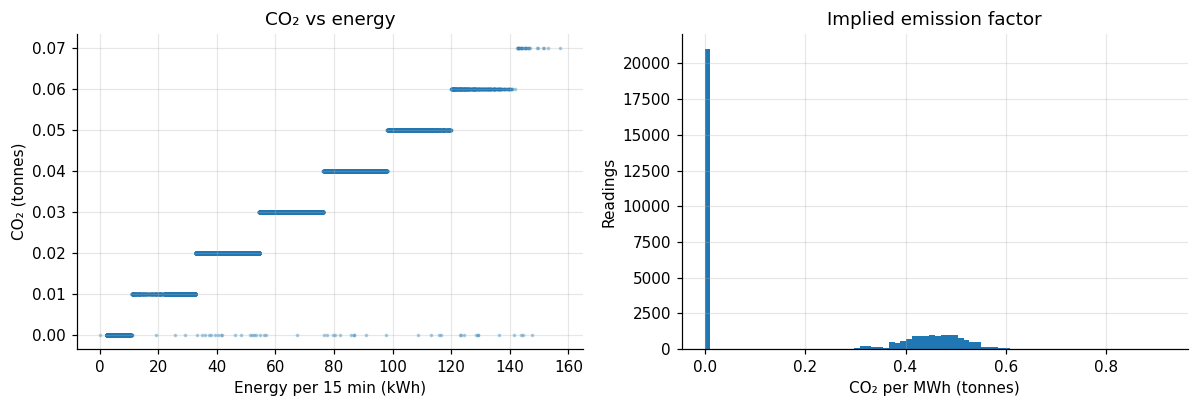


VERDICT: CO₂ is stored with very few distinct values (heavy rounding), so the implied factor scatters widely. Treat the column as CALCULATED and rounded, not measured.
Estimated fixed factor used by the dataset: 0.455 tCO2/MWh (for comparison, South Korea's grid factor is about 0.45)


In [8]:
nz = steel[steel["kwh"] > 0].copy()
nz["ratio_t_per_mwh"] = nz["co2_t"] / (nz["kwh"] / 1000)      # tonnes CO2 per MWh

print("Rows with energy > 0:", len(nz))
print("Rows where CO2 is exactly 0 but energy > 0:", int((nz["co2_t"] == 0).sum()))
print("Distinct CO2 values:", steel["co2_t"].nunique())
print(nz["ratio_t_per_mwh"].describe().round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(steel["kwh"], steel["co2_t"], s=2, alpha=0.3)
ax[0].set(xlabel="Energy per 15 min (kWh)", ylabel="CO₂ (tonnes)", title="CO₂ vs energy")
ax[1].hist(nz["ratio_t_per_mwh"], bins=80)
ax[1].set(xlabel="CO₂ per MWh (tonnes)", ylabel="Readings", title="Implied emission factor")
savefig("02_co2_check")

spread = nz["ratio_t_per_mwh"].std() / nz["ratio_t_per_mwh"].mean()
if steel["co2_t"].nunique() < 50 or spread > 0.5:
    verdict = ("CO₂ is stored with very few distinct values (heavy rounding), so the implied factor "
               "scatters widely. Treat the column as CALCULATED and rounded, not measured.")
elif spread < 0.02:
    verdict = "CO₂ ÷ energy is almost constant: the column was CALCULATED with one fixed factor."
else:
    verdict = "CO₂ ÷ energy varies noticeably: the column may contain MEASURED information."
print("\nVERDICT:", verdict)

# Estimate the hidden fixed factor: least-squares line through the origin
k = (steel["kwh"] * steel["co2_t"]).sum() / (steel["kwh"] ** 2).sum() * 1000
print(f"Estimated fixed factor used by the dataset: {k:.3f} tCO2/MWh "
      f"(for comparison, South Korea's grid factor is about 0.45)")

**Write the verdict into the thesis.** Either way, this work does **not** use the dataset's CO₂ column as the truth;
emissions are recomputed from energy × Indian grid factors (Parts 3–5), as stated in the Assumptions section.

## Part 3 — Grid emission factor (CEA, recent five years)
Row used: *Weighted Average Grid Emission Rate (Incl. RES, Captive)*, excluding imports.

2016-17    0.769
2017-18    0.753
2018-19    0.744
2019-20    0.712
2020-21    0.703
2021-22    0.715
2022-23    0.719
2023-24    0.729
2024-25    0.712
2025-26    0.678

Recent five years -> mean 0.711, std 0.019, range 0.678-0.729


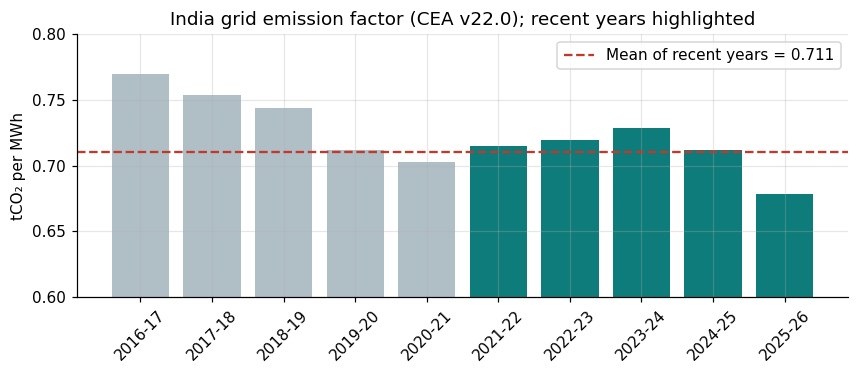

In [9]:
cea = pd.read_excel(CONFIG["cea_file"], sheet_name="Results", header=None)
mask = cea.apply(lambda c: c.astype(str).str.contains("Incl. RES", na=False))
r, c = list(zip(*mask.values.nonzero()))[0]                      # first match = excl. imports table
row = pd.to_numeric(cea.iloc[r, c + 1:], errors="coerce").dropna()[:10]
years = cea.iloc[r - 2, row.index].astype(str).tolist()
grid_ef_all = pd.Series(row.values, index=years, name="tCO2_per_MWh")

ef = grid_ef_all[CONFIG["cea_years"]]
EF_MEAN, EF_STD = float(ef.mean()), float(ef.std())
EF_MIN, EF_MAX = float(ef.min()), float(ef.max())
print(grid_ef_all.round(3).to_string())
print(f"\nRecent five years -> mean {EF_MEAN:.3f}, std {EF_STD:.3f}, range {EF_MIN:.3f}-{EF_MAX:.3f}")

def sample_grid_ef(n, rng=RNG):
    # Annual grid factor as a normal distribution, truncated to the observed range
    a, b = (EF_MIN - EF_MEAN) / EF_STD, (EF_MAX - EF_MEAN) / EF_STD
    return stats.truncnorm.rvs(a, b, loc=EF_MEAN, scale=EF_STD, size=n, random_state=rng)

fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ["#0E7C7B" if y in CONFIG["cea_years"] else "#B0BEC5" for y in grid_ef_all.index]
ax.bar(grid_ef_all.index, grid_ef_all.values, color=colors)
ax.axhline(EF_MEAN, color="#C0392B", ls="--", label=f"Mean of recent years = {EF_MEAN:.3f}")
ax.set(ylabel="tCO₂ per MWh", title="India grid emission factor (CEA v22.0); recent years highlighted",
       ylim=(0.6, 0.8))
ax.legend(); plt.xticks(rotation=45)
savefig("03_cea_factor")

## Part 4 — Hour-by-hour shape of grid carbon intensity (CarbonTracker India)
CEA gives one value per year. To let the scheduler reduce emissions by moving loads, we need to know which hours are
cleaner (solar, midday) and which are dirtier (evening, night).
Data: CarbonTracker India (CSEP), 5-minute all-India data, **FY 2025-26**. Timestamps from this service are already in India time (a UTC reading puts the solar dip at 17:00–18:00, which is impossible), so they are used as they are. A check below confirms the cleanest hour falls around midday.

*If the download fails* (the site's data service can change): open https://carbontracker.in/, download FY 2025-26 data
manually, save it as `data/raw/carbontracker_fy2025-26.parquet` (or .csv) with columns `timestamp` and `g_co2_per_kwh`, then rerun.

In [10]:
CT_FILE = f"{RAW}/carbontracker_fy2025-26.parquet"

def fetch_carbontracker(start, end, api):
    months = pd.date_range(pd.Timestamp(start).normalize().replace(day=1), end, freq="MS")
    frames = []
    for ms in months:
        me = min(ms + pd.offsets.MonthEnd(1) + pd.Timedelta(hours=23, minutes=55), pd.Timestamp(end))
        url = (f"{api}?start_time={ms:%Y-%m-%d}%20{ms:%H:%M:%S}"
               f"&end_time={me:%Y-%m-%d}%20{me:%H:%M:%S}&corrected_values=true")
        resp = requests.get(url, timeout=60)
        resp.raise_for_status()
        payload = resp.json()
        payload = json.loads(payload) if isinstance(payload, str) else payload
        v = payload["timeseries_values"]
        frames.append(pd.DataFrame({"timestamp": v["timestamps"], "g_co2_per_kwh": v["g_co2_per_kwh"],
                                    "total_generation": v.get("total_generation")}))
        print(f"  {ms:%Y-%m}: {len(frames[-1])} rows")
        time.sleep(2)                               # be polite to the service
    return pd.concat(frames, ignore_index=True)

if os.path.exists(CT_FILE):
    ct = pd.read_parquet(CT_FILE)
elif os.path.exists(CT_FILE.replace(".parquet", ".csv")):
    ct = pd.read_csv(CT_FILE.replace(".parquet", ".csv"))
else:
    print("Downloading CarbonTracker India data (12 months)...")
    ct = fetch_carbontracker(CONFIG["ct_start"], CONFIG["ct_end"], CONFIG["ct_api"])
    ct.to_parquet(CT_FILE, index=False)

ts_raw = pd.to_datetime(ct["timestamp"])
if getattr(ts_raw.dt, "tz", None) is not None:
    ts_raw = ts_raw.dt.tz_convert("Asia/Kolkata").dt.tz_localize(None)
elif not CONFIG["ct_timestamps_are_ist"]:
    ts_raw = ts_raw.dt.tz_localize("UTC").dt.tz_convert("Asia/Kolkata").dt.tz_localize(None)
ct["ts_ist"] = ts_raw
ct = ct.dropna(subset=["g_co2_per_kwh"])
ct = ct[ct["g_co2_per_kwh"] > 0]
print("CarbonTracker rows:", len(ct), "|", ct["ts_ist"].min(), "to", ct["ts_ist"].max())

CarbonTracker rows: 92551 | 2025-04-01 00:00:00 to 2026-03-31 23:50:00


summer: cleanest hour = 12:00 -> OK
winter: cleanest hour = 13:00 -> OK
hour       0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
season                                                                                                                                                                        
summer  1.106  1.106  1.108  1.112  1.114  1.119  1.111  1.049  0.946  0.868  0.823  0.804  0.799  0.800  0.820  0.861  0.924  1.002  1.063  1.081  1.090  1.095  1.097  1.101
winter  1.114  1.117  1.120  1.122  1.123  1.120  1.093  1.044  0.966  0.880  0.821  0.787  0.770  0.768  0.797  0.854  0.946  1.030  1.057  1.067  1.088  1.100  1.106  1.110


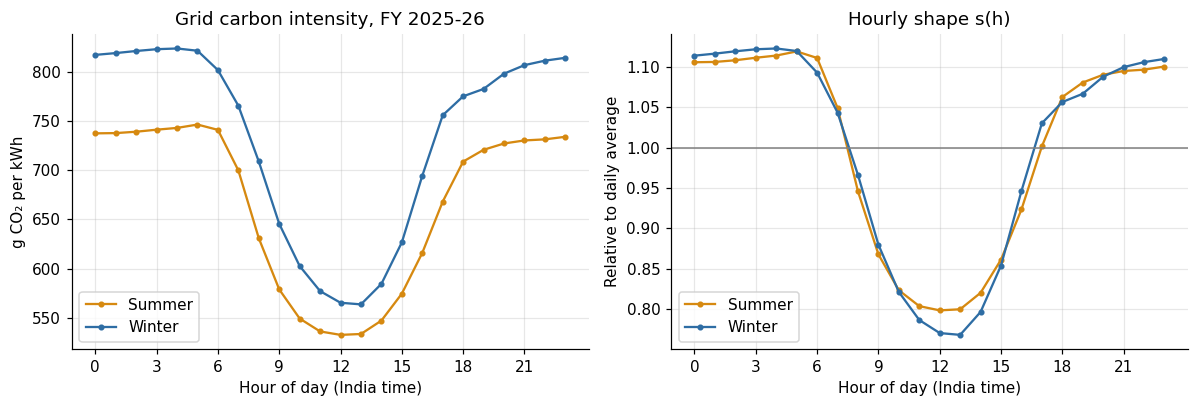

In [11]:
def season_of(month):
    return np.where(np.isin(month, CONFIG["summer_months"]), "summer", "winter")

ct["season"] = season_of(ct["ts_ist"].dt.month)
ct["hour"] = ct["ts_ist"].dt.hour
hourly = ct.groupby(["season", "hour"])["g_co2_per_kwh"].mean().unstack(0)

# Shape s(h): each hour relative to that season's daily average, so the shape averages to 1
SHAPE = hourly / hourly.mean()
SHAPE.to_csv(f"{PROC}/hourly_intensity_shape.csv")

# Sanity check: India's grid is cleanest when solar output peaks, around midday
for s_ in SHAPE.columns:
    h_min = int(SHAPE[s_].idxmin())
    ok = 10 <= h_min <= 15
    print(f"{s_}: cleanest hour = {h_min}:00 -> {'OK' if ok else 'CHECK THE TIME ZONE SETTING'}")
print(SHAPE.round(3).T.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for s, col in [("summer", "#D68910"), ("winter", "#2E6DA4")]:
    ax[0].plot(hourly.index, hourly[s], marker="o", ms=3, color=col, label=s.title())
    ax[1].plot(SHAPE.index, SHAPE[s], marker="o", ms=3, color=col, label=s.title())
ax[0].set(xlabel="Hour of day (India time)", ylabel="g CO₂ per kWh", title="Grid carbon intensity, FY 2025-26")
ax[1].axhline(1, color="grey", lw=1)
ax[1].set(xlabel="Hour of day (India time)", ylabel="Relative to daily average", title="Hourly shape s(h)")
for a in ax: a.legend(); a.set_xticks(range(0, 24, 3))
savefig("04_hourly_shape")

## Part 5 — Add the hourly emission factor and the electricity tariff to the steel data
* **Hourly factor** = CEA mean factor × hourly shape s(h) (season-specific).
* **Apparent energy** (what the tariff charges) = √(kWh² + kVArh²), using lagging reactive energy.
* **Cost** = kVAh × Rs 6.80 × (1 + time-of-day adjustment).

Each 15-minute reading is placed using the **start** of its interval.

In [12]:
def tod_adjustment(ts):
    # Time-of-day adjustment (e.g. -0.15, 0, +0.15) for each timestamp
    month, hour = ts.dt.month.values, ts.dt.hour.values
    adj = np.full(len(ts), np.nan)
    for season, slots in (("summer", CONFIG["tod_summer"]), ("winter", CONFIG["tod_winter"])):
        in_season = np.isin(month, CONFIG["summer_months"]) == (season == "summer")
        for start, end, a in slots:
            in_slot = (hour >= start) & (hour < end) if start < end else (hour >= start) | (hour < end)
            adj[in_season & in_slot] = a
    assert not np.isnan(adj).any(), "Some hours are not covered by the tariff table"
    return adj

steel["season"] = season_of(steel["ts"].dt.month)
steel["hour"] = steel["ts"].dt.hour
steel["tod_adj"] = tod_adjustment(steel["ts"])
steel["price_rs_per_kvah"] = CONFIG["energy_charge_rs_per_kvah"] * (1 + steel["tod_adj"])
steel["kvah"] = np.sqrt(steel["kwh"] ** 2 + steel["kvarh_lag"] ** 2)
steel["cost_rs"] = steel["kvah"] * steel["price_rs_per_kvah"]

shape_lookup = SHAPE.stack().rename("shape").reset_index()          # columns: hour, season, shape
steel = steel.merge(shape_lookup, on=["hour", "season"], how="left")
steel["grid_ef_t_per_mwh"] = EF_MEAN * steel["shape"]
steel["co2_india_t"] = steel["kwh"] / 1000 * steel["grid_ef_t_per_mwh"]   # emissions on India's grid

print("Tariff check (season, hour -> adjustment):")
print(steel.groupby(["season", "hour"])["tod_adj"].first().unstack(0).T.to_string())
print(f"\nTotal energy {steel['kwh'].sum()/1e3:,.0f} MWh | cost Rs {steel['cost_rs'].sum()/1e7:,.2f} crore | "
      f"emissions {steel['co2_india_t'].sum():,.0f} tCO₂")

Tariff check (season, hour -> adjustment):
hour      0     1     2     3     4     5     6     7     8     9    10   11   12   13   14   15   16    17    18    19    20    21    22    23
season                                                                                                                                         
summer  0.15  0.15  0.15  0.00  0.00 -0.15 -0.15 -0.15 -0.15 -0.15  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.00  0.00  0.15  0.15  0.15  0.15  0.15
winter -0.15 -0.15 -0.15 -0.15 -0.15  0.00  0.00  0.00  0.00  0.00  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.15  0.15  0.15  0.15  0.15  0.15 -0.15

Total energy 960 MWh | cost Rs 0.75 crore | emissions 630 tCO₂


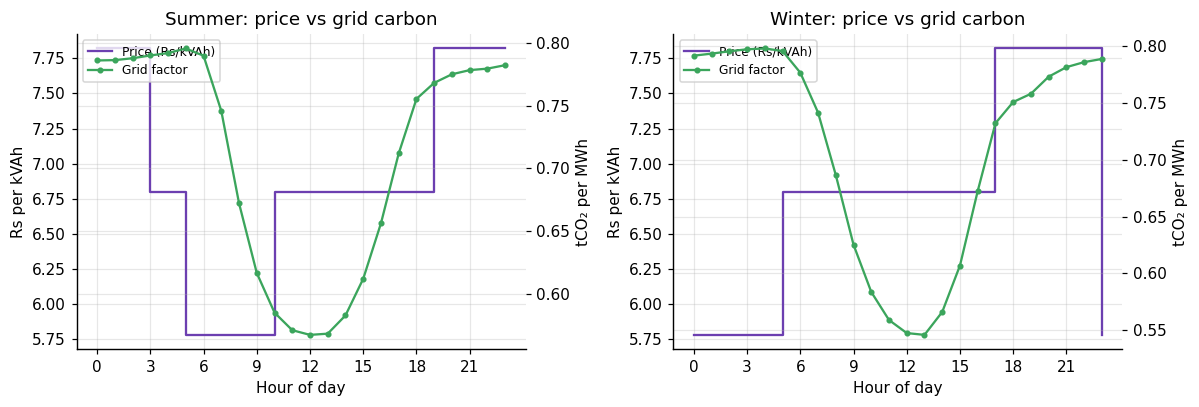

In [13]:
fig, ax1 = plt.subplots(1, 2, figsize=(11, 3.8))
for i, s in enumerate(["summer", "winter"]):
    p = steel[steel["season"] == s].groupby("hour")[["price_rs_per_kvah", "grid_ef_t_per_mwh"]].mean()
    a = ax1[i]
    a.step(p.index, p["price_rs_per_kvah"], where="post", color="#6C3FB0", label="Price (Rs/kVAh)")
    a.set(xlabel="Hour of day", ylabel="Rs per kVAh", title=f"{s.title()}: price vs grid carbon")
    b = a.twinx()
    b.plot(p.index, p["grid_ef_t_per_mwh"], color="#3BA55C", marker="o", ms=3, label="Grid factor")
    b.set_ylabel("tCO₂ per MWh")
    a.set_xticks(range(0, 24, 3))
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = b.get_legend_handles_labels()
    a.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
savefig("05_price_vs_carbon")

The plot above shows the **cost–carbon tension** in the thesis: the grid is cleanest around midday (solar), but the cheapest
hours are early morning in summer and night in winter, when the grid is dirtiest. Moving load to cut cost can raise emissions.

## Part 6 — Training, checking and testing periods
Split by time, never shuffled, so no model ever learns from the future.

In [14]:
def split_label(month, plan):
    out = np.full(len(month), "", dtype=object)
    for name, (m0, m1) in plan.items():
        out[(month >= m0) & (month <= m1)] = name
    return out

steel["split"] = split_label(steel["ts"].dt.month.values, CONFIG["steel_split"])
gas["split"] = gas["year"].map({y: k for k, ys in CONFIG["gt_split"].items() for y in ys})

print("Steel plant:\n", steel.groupby("split")["ts"].agg(["min", "max", "count"]), "\n")
print("Gas turbine:\n", gas.groupby("split")["year"].agg(["min", "max", "count"]))

Steel plant:
              min                 max  count
split                                      
calib 2018-09-01 2018-10-31 23:45:00   5856
test  2018-11-01 2018-12-31 23:45:00   5856
train 2018-01-01 2018-08-31 23:45:00  23328 

Gas turbine:
         min   max  count
split                   
calib  2013  2013   7152
test   2014  2015  14542
train  2011  2012  15039


## Part 7 — Daily emission limit
Limit = (1 − 5.5%) × average daily emissions of the same day type (weekday / weekend) in the **training** period.
5.5% is the median CCTS draft target for iron and steel (range 2.1–9.3%, also computed for the robustness check).

In [15]:
steel["day"] = steel["ts"].dt.normalize()
daily = (steel.groupby("day")
         .agg(co2_t=("co2_india_t", "sum"), kwh=("kwh", "sum"), cost_rs=("cost_rs", "sum"),
              week_status=("week_status", "first"), split=("split", "first"))
         .reset_index())
daily = daily[steel.groupby("day").size().values == 96]          # keep only complete days (96 readings)

base = daily[daily["split"] == "train"].groupby("week_status")["co2_t"].mean()
caps = pd.DataFrame({f"cap_{r*100:.1f}%": base * (1 - r) for r in CONFIG["cap_sensitivity"]})
caps.insert(0, "baseline_mean", base)
caps.to_csv(f"{PROC}/emission_caps.csv")
print(caps.round(2).to_string())

main_col = f"cap_{CONFIG['cap_reduction']*100:.1f}%"
daily["cap_t"] = daily["week_status"].map(caps[main_col])
daily["over_cap"] = daily["co2_t"] > daily["cap_t"]
print("\nShare of days ABOVE the 5.5% limit if nothing is changed:")
print(daily.groupby("split")["over_cap"].mean().round(3).to_string())

             baseline_mean  cap_2.1%  cap_5.5%  cap_9.3%
week_status                                             
Weekday               2.23      2.18      2.11      2.02
Weekend               0.77      0.75      0.73      0.70

Share of days ABOVE the 5.5% limit if nothing is changed:
split
calib    0.377
test     0.361
train    0.502


A high share above the limit when nothing is changed confirms the limit is **binding**.

### How the plant meets the limit: green power
Load shifting moves only about 9% of energy, and the plant's heaviest load already runs in the cleanest hours, so shifting
alone cannot deliver a 5.5% cut. The plant therefore also **buys green power** (UP discom green tariff, Rs 0.34 per kWh extra;
cross-checked against the REC exchange price of Rs 340 per MWh = Rs 0.34 per kWh). Green energy counts as zero emissions.

If a share *f* of the day's electricity is bought green, emissions become (1 − *f*) × grid emissions. With perfect knowledge
of the day's emissions, the share needed is *f* = max(0, 1 − limit / emissions). In reality the day's emissions must be
**forecast** — that is where the 95% ranges come in (notebook 04).

In [16]:
daily["green_share_needed"] = np.clip(1 - daily["cap_t"] / daily["co2_t"], 0, 1)
daily["green_cost_rs"] = daily["green_share_needed"] * daily["kwh"] * CONFIG["green_premium_rs_per_kwh"]

summary = daily.groupby("split").agg(days=("day", "count"),
                                     share_over=("over_cap", "mean"),
                                     avg_green_share_when_over=("green_share_needed", lambda x: x[x > 0].mean()),
                                     green_cost_rs=("green_cost_rs", "sum"),
                                     energy_cost_rs=("cost_rs", "sum"))
summary["green_cost_as_%_of_bill"] = 100 * summary["green_cost_rs"] / summary["energy_cost_rs"]
print("With PERFECT knowledge of each day's emissions (best case, not achievable in practice):")
print(summary.round(3).to_string())

With PERFECT knowledge of each day's emissions (best case, not achievable in practice):
       days  share_over  avg_green_share_when_over  green_cost_rs  energy_cost_rs  green_cost_as_%_of_bill
split                                                                                                     
calib    61       0.377                      0.209       4928.177     1165359.607                    0.423
test     61       0.361                      0.220       5029.597     1136642.072                    0.442
train   243       0.502                      0.256      43427.717     5167321.267                    0.840


## Part 8 — Exploration plots

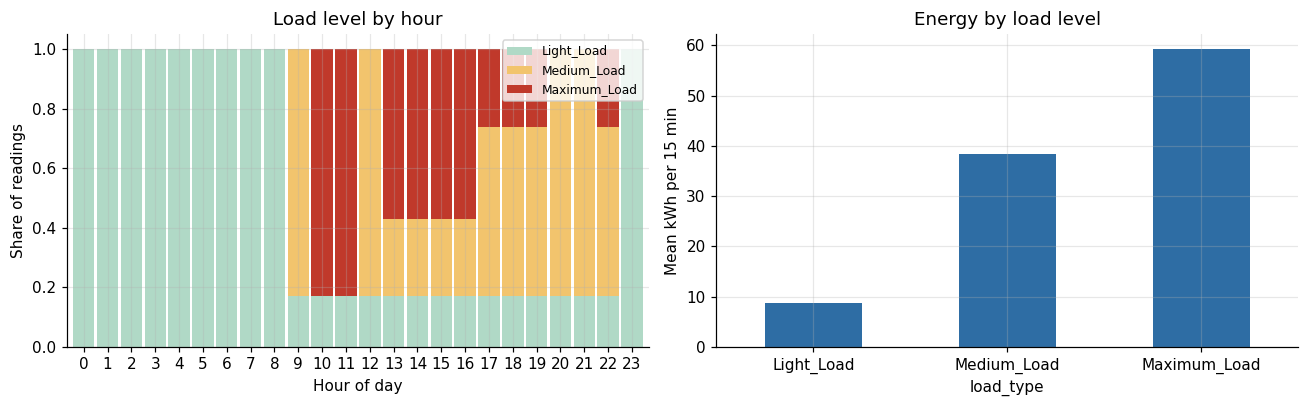

Flexible energy (20% of maximum-load energy): 86 MWh = 9.0% of all energy


In [17]:
order = ["Light_Load", "Medium_Load", "Maximum_Load"]
share = (steel.groupby(["hour", "load_type"]).size().unstack(fill_value=0)
         .reindex(columns=[o for o in order if o in steel["load_type"].unique()]))
share = share.div(share.sum(axis=1), axis=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
share.plot.bar(stacked=True, ax=ax[0], width=0.9, rot=0, color=["#B0D9C6", "#F2C46D", "#C0392B"])
ax[0].set(xlabel="Hour of day", ylabel="Share of readings", title="Load level by hour")
ax[0].legend(fontsize=8)
steel.groupby("load_type")["kwh"].mean().reindex(share.columns).plot.bar(ax=ax[1], color="#2E6DA4", rot=0)
ax[1].set(ylabel="Mean kWh per 15 min", title="Energy by load level")
savefig("08_load_levels")

flex = steel.loc[steel["load_type"] == "Maximum_Load", "kwh"].sum() * CONFIG["flex_share"]
print(f"Flexible energy (20% of maximum-load energy): {flex/1e3:,.0f} MWh "
      f"= {flex / steel['kwh'].sum():.1%} of all energy")

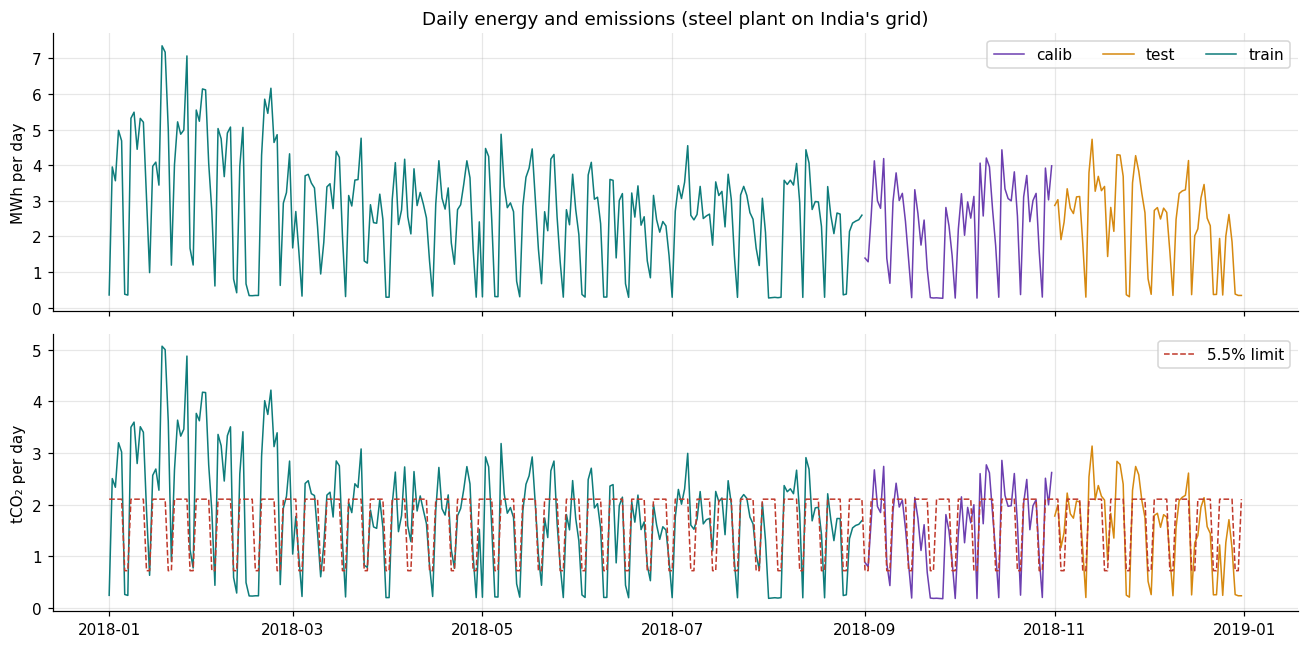

In [18]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
colors = {"train": "#0E7C7B", "calib": "#6C3FB0", "test": "#D68910"}
for sp, g in daily.groupby("split"):
    ax[0].plot(g["day"], g["kwh"] / 1000, color=colors[sp], lw=1, label=sp)
    ax[1].plot(g["day"], g["co2_t"], color=colors[sp], lw=1)
ax[1].plot(daily["day"], daily["cap_t"], color="#C0392B", lw=1, ls="--", label="5.5% limit")
ax[0].set(ylabel="MWh per day", title="Daily energy and emissions (steel plant on India's grid)")
ax[1].set(ylabel="tCO₂ per day")
ax[0].legend(ncol=3); ax[1].legend()
savefig("08_daily_series")

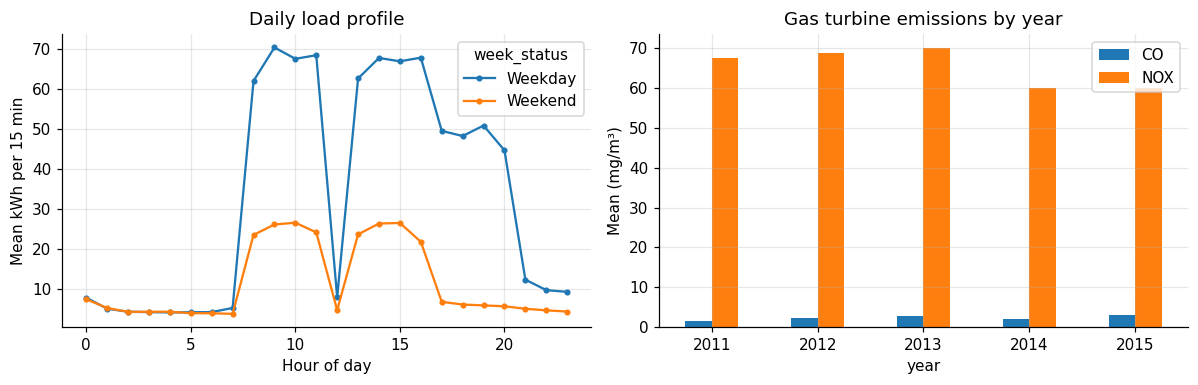

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
prof = steel.groupby(["week_status", "hour"])["kwh"].mean().unstack(0)
prof.plot(ax=ax[0], marker="o", ms=3)
ax[0].set(xlabel="Hour of day", ylabel="Mean kWh per 15 min", title="Daily load profile")
gas.groupby("year")[["CO", "NOX"]].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set(ylabel="Mean (mg/m³)", title="Gas turbine emissions by year")
savefig("08_profiles")

## Part 9 — Save prepared data to Drive

In [20]:
keep = ["ts", "ts_end", "kwh", "kvarh_lag", "kvarh_lead", "pf_lag", "pf_lead", "co2_t", "nsm",
        "week_status", "day_of_week", "load_type", "season", "hour", "tod_adj", "price_rs_per_kvah",
        "kvah", "cost_rs", "shape", "grid_ef_t_per_mwh", "co2_india_t", "split"]
steel[[k for k in keep if k in steel.columns]].to_parquet(f"{PROC}/steel_prepared.parquet", index=False)
daily.to_parquet(f"{PROC}/steel_daily.parquet", index=False)
gas.to_parquet(f"{PROC}/gas_prepared.parquet", index=False)
pd.Series({"ef_mean": EF_MEAN, "ef_std": EF_STD, "ef_min": EF_MIN, "ef_max": EF_MAX}).to_json(
    f"{PROC}/grid_ef_stats.json")

for f in sorted(glob.glob(f"{PROC}/*")):
    print(f"{os.path.basename(f):35s} {os.path.getsize(f)/1024:8.1f} KB")
print("\nFigures saved in", FIGS)

emission_caps.csv                        0.2 KB
gas_prepared.parquet                  1455.6 KB
grid_ef_stats.json                       0.1 KB
hourly_intensity_shape.csv               1.0 KB
steel_daily.parquet                     21.3 KB
steel_prepared.parquet                1549.7 KB

Figures saved in /content/drive/MyDrive/thesis/results/figures


### Save this notebook to GitHub
File → **Save a copy in GitHub** → choose your thesis repository. Do this after each working session.

### What comes next
**Notebook 02 — Baseline forecasting:** XGBoost and LSTM models that predict energy (and therefore CO₂) one step ahead,
trained on the training period and evaluated on the test period. These are the single-number baselines the
uncertainty-aware models will be compared with.